# TÁCH TỪ TIẾNG VIỆT BẰNG FMM, BMM VÀ HMM–VITERBI

Notebook gồm: chuẩn bị dữ liệu, xây dựng từ điển, cài đặt FMM/BMM, huấn luyện HMM, giải mã Viterbi, đánh giá Precision–Recall–F1, kiểm thử và các thử nghiệm UNK/chuẩn hóa chữ hoa-thường.

**Cách chạy:** chạy lần lượt từ trên xuống dưới. Khi được yêu cầu, tải lên file `dataset.csv` có hai cột `sentence` và `segmented`. Trong `segmented`, các tiếng thuộc cùng một từ được nối bằng dấu gạch dưới `_`.

Ví dụ:
- `sentence`: `Tôi đang học công nghệ thông tin`
- `segmented`: `Tôi đang học công_nghệ thông_tin`

Lưu ý: tập dữ liệu gồm 120 câu do người thực hiện gán nhãn; cần kiểm tra chất lượng nhãn thủ công trước khi xem đây là dữ liệu chuẩn chuyên gia.

## 1. Chuẩn bị thư viện và dữ liệu

In [1]:
import math
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from google.colab import files
uploaded = files.upload()  # Chọn dataset.csv

Saving dataset.csv to dataset.csv


In [2]:
# Đọc dữ liệu
data = pd.read_csv("dataset.csv", encoding="utf-8-sig")

required_columns = {"sentence", "segmented"}
if not required_columns.issubset(data.columns):
    raise ValueError("CSV phải có hai cột: sentence và segmented")

data = data.dropna(subset=["sentence", "segmented"]).copy()
data["sentence"] = data["sentence"].astype(str).str.strip()
data["segmented"] = data["segmented"].astype(str).str.strip()

print(data.head())
print("Tổng số câu:", len(data))

               sentence             segmented
0      Tôi đang học bài      Tôi đang học bài
1  Hôm nay trời rất đẹp  Hôm_nay trời rất đẹp
2   Tôi thích nghe nhạc   Tôi thích nghe nhạc
3       Mẹ đang nấu cơm       Mẹ đang nấu cơm
4     Bố đi làm từ sáng     Bố đi làm từ sáng
Tổng số câu: 120


In [3]:
# Kiểm tra dữ liệu gán nhãn có khôi phục đúng chuỗi tiếng ban đầu không
alignment_errors = []
for idx, row in data.iterrows():
    original = row["sentence"].split()
    reconstructed = []
    for word in row["segmented"].split():
        reconstructed.extend(word.split("_"))
    if original != reconstructed:
        alignment_errors.append((idx, row["sentence"], row["segmented"]))

print("Số câu không khớp:", len(alignment_errors))
if alignment_errors:
    print("Một số lỗi:", alignment_errors[:5])
    raise ValueError("Cần sửa các dòng gán nhãn không khớp trước khi huấn luyện.")

Số câu không khớp: 0


In [4]:
# Chia dữ liệu 80% Train và 20% Test
train, test = train_test_split(
    data, test_size=0.2, random_state=42
)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

train.to_csv("train.csv", index=False, encoding="utf-8-sig")
test.to_csv("test.csv", index=False, encoding="utf-8-sig")

print("Số câu Train:", len(train))
print("Số câu Test:", len(test))

Số câu Train: 96
Số câu Test: 24


## 2. Xây dựng từ điển từ tập Train

In [5]:
# Chỉ dùng dữ liệu Train để tránh rò rỉ thông tin từ tập Test
dictionary = set()
for segmented in train["segmented"]:
    dictionary.update(segmented.split())

with open("dictionary.txt", "w", encoding="utf-8") as f:
    for word in sorted(dictionary):
        f.write(word + "\n")

print("Số từ trong từ điển:", len(dictionary))
print("Một số từ:", sorted(dictionary)[:20])

Số từ trong từ điển: 302
Một số từ: ['An_toàn', 'Anh_trai', 'Biển', 'Bạn', 'C++', 'Chuyến', 'Chúng_tôi', 'Cuối_tuần', 'Cuộc_sống', 'Các', 'Cô_giáo', 'Công_nghệ', 'Công_ty', 'Du_khách', 'Du_lịch', 'Dữ_liệu', 'Em', 'Gia_đình', 'Giao_thông', 'Giáo_dục']


## 3. Phương pháp FMM (Maximum Matching từ trái sang phải)

In [6]:
def fmm(sentence, dictionary):
    syllables = sentence.split()
    result = []
    i = 0

    while i < len(syllables):
        found = False
        # Thử từ dài nhất trước, bắt đầu tại vị trí i
        for j in range(len(syllables), i, -1):
            candidate = "_".join(syllables[i:j])
            if candidate in dictionary:
                result.append(candidate)
                i = j
                found = True
                break

        # Không tìm thấy từ ghép thì giữ nguyên một tiếng
        if not found:
            result.append(syllables[i])
            i += 1

    return " ".join(result)

example = "Tôi đang học công nghệ thông tin"
print("Câu đầu vào:", example)
print("FMM:", fmm(example, dictionary))

Câu đầu vào: Tôi đang học công nghệ thông tin
FMM: Tôi đang học công_nghệ thông_tin


## 4. Phương pháp BMM (Maximum Matching từ phải sang trái)

In [7]:
def bmm(sentence, dictionary):
    syllables = sentence.split()
    result = []
    i = len(syllables) - 1

    while i >= 0:
        found = False
        # Thử cụm dài nhất kết thúc tại vị trí i
        for j in range(0, i + 1):
            candidate = "_".join(syllables[j:i + 1])
            if candidate in dictionary:
                result.insert(0, candidate)
                i = j - 1
                found = True
                break

        if not found:
            result.insert(0, syllables[i])
            i -= 1

    return " ".join(result)

print("Câu đầu vào:", example)
print("BMM:", bmm(example, dictionary))

Câu đầu vào: Tôi đang học công nghệ thông tin
BMM: Tôi đang học công_nghệ thông_tin


In [8]:
# Ví dụ minh họa cơ chế FMM và BMM có thể cho kết quả khác nhau.
# Đây là từ điển giả lập để giải thích thuật toán, không phải từ điển dữ liệu thật.
toy_dictionary = {"a_b", "b_c"}
toy_sentence = "a b c"
print("FMM:", fmm(toy_sentence, toy_dictionary))
print("BMM:", bmm(toy_sentence, toy_dictionary))

FMM: a_b c
BMM: a b_c


## 5. Hàm đánh giá Precision, Recall và F1-score

In [9]:
def get_words_and_positions(segmented):
    """Trả về các khoảng vị trí tiếng của từng từ trong câu đã tách."""
    words = segmented.split()
    spans = set()
    position = 0

    for word in words:
        length = len(word.split("_"))
        spans.add((position, position + length))
        position += length

    return spans


def evaluate(predictions, actual):
    if len(predictions) != len(actual):
        raise ValueError("Số dự đoán và số đáp án không bằng nhau.")

    TP = FP = FN = 0
    for pred, gold in zip(predictions, actual):
        pred_words = get_words_and_positions(pred)
        gold_words = get_words_and_positions(gold)
        TP += len(pred_words & gold_words)
        FP += len(pred_words - gold_words)
        FN += len(gold_words - pred_words)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return precision, recall, f1


def print_metrics(name, predictions, gold):
    p, r, f = evaluate(predictions, gold)
    print(name)
    print("Precision:", round(p, 4))
    print("Recall:", round(r, 4))
    print("F1-score:", round(f, 4))
    return p, r, f

## 6. Đánh giá FMM và BMM trên tập Test

In [10]:
test_sentences = test["sentence"].tolist()
test_gold = test["segmented"].tolist()

fmm_results = [fmm(s, dictionary) for s in test_sentences]
bmm_results = [bmm(s, dictionary) for s in test_sentences]

p_fmm, r_fmm, f1_fmm = print_metrics("===== FMM =====", fmm_results, test_gold)
p_bmm, r_bmm, f1_bmm = print_metrics("===== BMM =====", bmm_results, test_gold)

===== FMM =====
Precision: 0.5698
Recall: 0.7259
F1-score: 0.6384
===== BMM =====
Precision: 0.5698
Recall: 0.7259
F1-score: 0.6384


## 7. Huấn luyện HMM với hai trạng thái B/I

- **B (Begin):** tiếng bắt đầu một từ.
- **I (Inside):** tiếng nằm bên trong một từ nhiều tiếng.

Xác suất chuyển trạng thái được chuẩn hóa theo tổng số lần đi ra từ trạng thái trước đó. Xác suất phát xạ được chuẩn hóa theo tổng số lần trạng thái xuất hiện. Dùng Laplace Smoothing với `alpha = 1`.

In [11]:
states = ["B", "I"]
alpha = 1

# Đếm trạng thái bắt đầu, chuyển trạng thái và phát xạ
start_counts = Counter()
transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
state_counts = Counter()
vocabulary = set()

for sentence, segmented in zip(train["sentence"], train["segmented"]):
    syllables = sentence.split()
    labels = []

    for word in segmented.split():
        parts = word.split("_")
        labels.extend(["B"] + ["I"] * (len(parts) - 1))

    if len(syllables) != len(labels):
        raise ValueError("Số tiếng và số nhãn không khớp!")
    if not labels:
        continue

    start_counts[labels[0]] += 1

    for i, (syllable, state) in enumerate(zip(syllables, labels)):
        vocabulary.add(syllable)
        emission_counts[state][syllable] += 1
        state_counts[state] += 1
        if i > 0:
            transition_counts[labels[i - 1]][state] += 1

# UNK có trong không gian từ vựng; ở mô hình gốc chưa được gom mẫu hiếm vào UNK.
vocabulary.add("<UNK>")

start_prob = {}
transition_prob = {}
emission_prob = {}

for state in states:
    start_prob[state] = (start_counts[state] + alpha) / (
        sum(start_counts.values()) + alpha * len(states)
    )

for previous_state in states:
    transition_prob[previous_state] = {}
    outgoing_total = sum(transition_counts[previous_state].values())
    for state in states:
        transition_prob[previous_state][state] = (
            transition_counts[previous_state][state] + alpha
        ) / (outgoing_total + alpha * len(states))

for state in states:
    emission_prob[state] = {}
    for syllable in vocabulary:
        emission_prob[state][syllable] = (
            emission_counts[state][syllable] + alpha
        ) / (state_counts[state] + alpha * len(vocabulary))

print("Đã huấn luyện HMM.")
print("Số tiếng trong vocabulary (có tính <UNK>):", len(vocabulary))

Đã huấn luyện HMM.
Số tiếng trong vocabulary (có tính <UNK>): 387


## 8. Giải mã HMM bằng thuật toán Viterbi

In [12]:
def viterbi(sentence):
    syllables = sentence.split()
    n = len(syllables)
    if n == 0:
        return ""

    dp = [{} for _ in range(n)]
    backpointer = [{} for _ in range(n)]

    # Khởi tạo
    first = syllables[0] if syllables[0] in vocabulary else "<UNK>"
    for state in states:
        dp[0][state] = math.log(start_prob[state]) + math.log(emission_prob[state][first])

    # Quy hoạch động
    for i in range(1, n):
        word = syllables[i] if syllables[i] in vocabulary else "<UNK>"
        for state in states:
            best_score = float("-inf")
            best_previous = None
            for previous_state in states:
                score = (
                    dp[i - 1][previous_state]
                    + math.log(transition_prob[previous_state][state])
                    + math.log(emission_prob[state][word])
                )
                if score > best_score:
                    best_score = score
                    best_previous = previous_state
            dp[i][state] = best_score
            backpointer[i][state] = best_previous

    # Chọn trạng thái cuối và truy vết
    last_state = max(dp[-1], key=dp[-1].get)
    best_path = [last_state]
    for i in range(n - 1, 0, -1):
        last_state = backpointer[i][last_state]
        best_path.append(last_state)
    best_path.reverse()

    # B ghép bằng dấu cách, I ghép bằng dấu gạch dưới
    result = []
    for i, syllable in enumerate(syllables):
        if i > 0:
            result.append(" " if best_path[i] == "B" else "_")
        result.append(syllable)
    return "".join(result)

print("Câu đầu vào:", example)
print("HMM-Viterbi:", viterbi(example))

Câu đầu vào: Tôi đang học công nghệ thông tin
HMM-Viterbi: Tôi đang_học công_nghệ thông_tin


## 9. Đánh giá HMM và so sánh ba phương pháp

In [13]:
hmm_results = [viterbi(s) for s in test_sentences]
p_hmm, r_hmm, f1_hmm = print_metrics("===== HMM-VITERBI =====", hmm_results, test_gold)

results = pd.DataFrame({
    "Phương pháp": ["FMM", "BMM", "HMM-Viterbi"],
    "Precision": [p_fmm, p_bmm, p_hmm],
    "Recall": [r_fmm, r_bmm, r_hmm],
    "F1-score": [f1_fmm, f1_bmm, f1_hmm]
})

display(results.round(4))
results.to_csv("comparison_results.csv", index=False, encoding="utf-8-sig")

===== HMM-VITERBI =====
Precision: 0.7395
Recall: 0.6519
F1-score: 0.6929


,Phương pháp,Precision,Recall,F1-score
0,FMM,0.5698,0.7259,0.6384
1,BMM,0.5698,0.7259,0.6384
2,HMM-Viterbi,0.7395,0.6519,0.6929


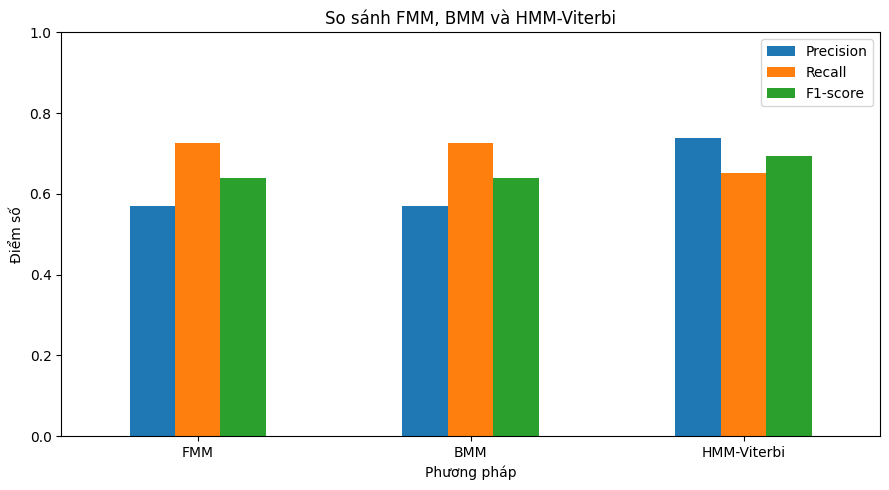

In [14]:
ax = results.set_index("Phương pháp")[["Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
ax.set_title("So sánh FMM, BMM và HMM-Viterbi")
ax.set_ylabel("Điểm số")
ax.set_xlabel("Phương pháp")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Kiểm thử chương trình

In [15]:
# Unit Test theo ví dụ đã dùng trong quá trình xây dựng
sentence_test = "học sinh"
expected = "học_sinh"
actual_prediction = viterbi(sentence_test)
assert actual_prediction == expected, f"Mong đợi {expected}, nhận được {actual_prediction}"
print("Unit Test học sinh: Thành công!")

# Kiểm tra câu rỗng và bảo toàn chuỗi tiếng đầu vào
assert viterbi("") == ""
check_sentences = ["Tôi", "học sinh", "Tôi đang học công nghệ thông tin", "xyzabc"]
for s in check_sentences:
    output = viterbi(s)
    original_syllables = s.split()
    output_syllables = [part for word in output.split() for part in word.split("_")]
    assert original_syllables == output_syllables, f"Lỗi bảo toàn tiếng: {s}"
print("Kiểm tra bảo toàn tiếng: Thành công!")

Unit Test học sinh: Thành công!
Kiểm tra bảo toàn tiếng: Thành công!


## 11. Phân tích lỗi và dữ liệu

In [16]:
# Đếm TP, FP, FN cho HMM chính
TP = FP = FN = 0
for gold, pred in zip(test_gold, hmm_results):
    gold_spans = get_words_and_positions(gold)
    pred_spans = get_words_and_positions(pred)
    TP += len(gold_spans & pred_spans)
    FP += len(pred_spans - gold_spans)
    FN += len(gold_spans - pred_spans)

print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print("Số câu Test có ít nhất một ranh giới sai:", sum(
    get_words_and_positions(g) != get_words_and_positions(p)
    for g, p in zip(test_gold, hmm_results)
), "/", len(test_gold))

TP: 88
FP: 31
FN: 47
Số câu Test có ít nhất một ranh giới sai: 16 / 24


In [17]:
# Thống kê tiếng chưa xuất hiện trong Train
train_syllables = set()
for sentence in train["sentence"]:
    train_syllables.update(sentence.split())

unknown_counts = Counter(
    syllable
    for sentence in test_sentences
    for syllable in sentence.split()
    if syllable not in train_syllables
)
total_test_syllables = sum(len(s.split()) for s in test_sentences)
unknown_occurrences = sum(unknown_counts.values())

print("Số tiếng khác nhau trong Train:", len(train_syllables))
print("Số loại tiếng chưa biết trong Test:", len(unknown_counts))
print("Số lần xuất hiện tiếng chưa biết:", unknown_occurrences)
print("Tổng số tiếng trong Test:", total_test_syllables)
print("Tỷ lệ tiếng chưa biết:", round(unknown_occurrences / total_test_syllables * 100, 2), "%")
print("Các tiếng chưa biết:", sorted(unknown_counts))

Số tiếng khác nhau trong Train: 386
Số loại tiếng chưa biết trong Test: 49
Số lần xuất hiện tiếng chưa biết: 54
Tổng số tiếng trong Test: 199
Tỷ lệ tiếng chưa biết: 27.14 %
Các tiếng chưa biết: ['Buổi', 'Bảo', 'Bắc', 'Bố', 'Doanh', 'Giá', 'Hệ', 'Internet', 'Nhiều', 'Thư', 'Thị', 'chiếc', 'chiến', 'cả', 'cửa', 'dạy', 'dậy', 'dự', 'dựng', 'gần', 'hè', 'khảo', 'lược', 'mua', 'môi', 'mùa', 'mật', 'mọi', 'một', 'núi', 'nằm', 'phía', 'quyền', 'sạn', 'sớm', 'tháng', 'thống', 'tiện', 'trung', 'trước', 'từ', 'vùng', 'xây', 'ý', 'ăn', 'đảm', 'định', 'đổi', 'ổn']


In [18]:
# Hiển thị các câu HMM dự đoán sai để phân tích
wrong_rows = []
for sentence, gold, pred in zip(test_sentences, test_gold, hmm_results):
    if get_words_and_positions(gold) != get_words_and_positions(pred):
        wrong_rows.append({"Câu gốc": sentence, "Đáp án": gold, "HMM": pred})

wrong_df = pd.DataFrame(wrong_rows)
print("Số câu dự đoán sai:", len(wrong_df))
display(wrong_df)

Số câu dự đoán sai: 16


,Câu gốc,Đáp án,HMM
0,Bảo vệ môi trường là trách nhiệm của mọi người,Bảo_vệ môi_trường là trách_nhiệm của mọi_người,Bảo_vệ môi_trường là trách_nhiệm của_mọi người
1,Bố đi làm từ sáng,Bố đi làm từ sáng,Bố_đi làm_từ sáng
2,Nhiều người lựa chọn phương tiện công cộng,Nhiều người lựa_chọn phương_tiện công_cộng,Nhiều_người lựa_chọn phương_tiện công_cộng
3,Thị trường đang có nhiều biến động,Thị_trường đang có nhiều biến_động,Thị_trường đang có nhiều_biến động
4,Buổi sáng tôi thức dậy sớm,Buổi sáng tôi thức_dậy sớm,Buổi_sáng tôi_thức dậy_sớm
5,Việt Nam có nhiều cảnh đẹp,Việt_Nam có nhiều cảnh_đẹp,Việt_Nam có nhiều_cảnh đẹp
6,Giáo viên cần đổi mới phương pháp giảng dạy,Giáo_viên cần đổi_mới phương_pháp giảng_dạy,Giáo_viên cần_đổi mới_phương pháp_giảng dạy
7,Tôi cần mua một chiếc điện thoại,Tôi cần mua một chiếc điện_thoại,Tôi cần_mua một_chiếc điện_thoại
8,Doanh nghiệp cần xây dựng chiến lược kinh doanh,Doanh_nghiệp cần xây_dựng chiến_lược kinh_doanh,Doanh_nghiệp cần_xây dựng_chiến lược kinh_doanh
9,Tôi ăn sáng trước khi đi học,Tôi ăn_sáng trước khi đi học,Tôi_ăn sáng_trước khi đi_học


## 12. Thử nghiệm cải tiến 1: Gom tiếng hiếm vào UNK

Hai ngưỡng được khảo sát:
- **Ngưỡng 2:** tiếng xuất hiện dưới 2 lần trong Train được ánh xạ thành `<UNK>`.
- **Ngưỡng 3:** tiếng xuất hiện dưới 3 lần trong Train được ánh xạ thành `<UNK>`.

Đây là các thử nghiệm khảo sát trên cùng tập Test đã dùng trước đó; vì vậy không dùng chúng để tuyên bố một mô hình tối ưu khách quan. Với nghiên cứu tiếp theo, nên có tập Validation riêng để chọn ngưỡng.

In [19]:
def train_hmm(min_count=None, lowercase=False, alpha=1):
    """Huấn luyện HMM B/I. min_count=None giữ nguyên từng tiếng;
    min_count=k gom tiếng có tần suất < k vào <UNK>."""
    normalize = (lambda x: x.lower()) if lowercase else (lambda x: x)
    counts = Counter()
    for sentence in train["sentence"]:
        counts.update(normalize(s) for s in sentence.split())

    kept = set(counts) if min_count is None else {
        s for s, count in counts.items() if count >= min_count
    }
    vocab = set(kept) | {"<UNK>"}

    starts = Counter()
    transitions = defaultdict(Counter)
    emissions = defaultdict(Counter)
    states_count = Counter()

    for sentence, segmented in zip(train["sentence"], train["segmented"]):
        syllables = [normalize(s) for s in sentence.split()]
        labels = []
        for word in segmented.split():
            parts = word.split("_")
            labels.extend(["B"] + ["I"] * (len(parts) - 1))
        if len(syllables) != len(labels):
            raise ValueError("Số tiếng và số nhãn không khớp!")
        if not labels:
            continue
        starts[labels[0]] += 1
        mapped = [s if s in kept else "<UNK>" for s in syllables]
        for i, (syllable, state) in enumerate(zip(mapped, labels)):
            emissions[state][syllable] += 1
            states_count[state] += 1
            if i > 0:
                transitions[labels[i - 1]][state] += 1

    start_p = {}
    trans_p = {}
    emit_p = {}
    for state in states:
        start_p[state] = (starts[state] + alpha) / (sum(starts.values()) + alpha * len(states))
    for prev in states:
        trans_p[prev] = {}
        total = sum(transitions[prev].values())
        for state in states:
            trans_p[prev][state] = (transitions[prev][state] + alpha) / (total + alpha * len(states))
    for state in states:
        emit_p[state] = {}
        for syllable in vocab:
            emit_p[state][syllable] = (emissions[state][syllable] + alpha) / (
                states_count[state] + alpha * len(vocab)
            )

    return {
        "kept": kept, "vocabulary": vocab,
        "start_prob": start_p, "transition_prob": trans_p,
        "emission_prob": emit_p, "lowercase": lowercase,
        "min_count": min_count, "alpha": alpha,
        "counts": counts, "emission_counts": emissions
    }


def decode_hmm(sentence, model):
    syllables_original = sentence.split()
    if not syllables_original:
        return ""
    normalize = (lambda x: x.lower()) if model["lowercase"] else (lambda x: x)
    mapped = []
    for s in syllables_original:
        normalized = normalize(s)
        mapped.append(normalized if normalized in model["kept"] else "<UNK>")

    n = len(mapped)
    dp = [{} for _ in range(n)]
    back = [{} for _ in range(n)]
    for state in states:
        dp[0][state] = math.log(model["start_prob"][state]) + math.log(
            model["emission_prob"][state][mapped[0]]
        )
    for i in range(1, n):
        for state in states:
            candidates = [
                (dp[i - 1][prev] + math.log(model["transition_prob"][prev][state])
                 + math.log(model["emission_prob"][state][mapped[i]]), prev)
                for prev in states
            ]
            dp[i][state], back[i][state] = max(candidates, key=lambda item: item[0])
    last = max(dp[-1], key=dp[-1].get)
    path = [last]
    for i in range(n - 1, 0, -1):
        last = back[i][last]
        path.append(last)
    path.reverse()

    result = []
    for i, syllable in enumerate(syllables_original):
        if i:
            result.append(" " if path[i] == "B" else "_")
        result.append(syllable)
    return "".join(result)

In [20]:
# Huấn luyện và đánh giá hai ngưỡng UNK
model_unk2 = train_hmm(min_count=2)
model_unk3 = train_hmm(min_count=3)

pred_unk2 = [decode_hmm(s, model_unk2) for s in test_sentences]
pred_unk3 = [decode_hmm(s, model_unk3) for s in test_sentences]

p_unk2, r_unk2, f1_unk2 = print_metrics("HMM UNK ngưỡng 2", pred_unk2, test_gold)
p_unk3, r_unk3, f1_unk3 = print_metrics("HMM UNK ngưỡng 3", pred_unk3, test_gold)

print("Số loại tiếng được giữ (ngưỡng 2):", len(model_unk2["kept"]))
print("Số loại tiếng được gom vào UNK (ngưỡng 2):", len(model_unk2["counts"]) - len(model_unk2["kept"]))
print("Số loại tiếng được giữ (ngưỡng 3):", len(model_unk3["kept"]))
print("Số loại tiếng được gom vào UNK (ngưỡng 3):", len(model_unk3["counts"]) - len(model_unk3["kept"]))
print("Số mẫu huấn luyện đã ánh xạ vào UNK (ngưỡng 2):",
      sum(model_unk2["emission_counts"][s]["<UNK>"] for s in states))

HMM UNK ngưỡng 2
Precision: 0.6129
Recall: 0.563
F1-score: 0.5869
HMM UNK ngưỡng 3
Precision: 0.563
Recall: 0.4963
F1-score: 0.5276
Số loại tiếng được giữ (ngưỡng 2): 168
Số loại tiếng được gom vào UNK (ngưỡng 2): 218
Số loại tiếng được giữ (ngưỡng 3): 93
Số loại tiếng được gom vào UNK (ngưỡng 3): 293
Số mẫu huấn luyện đã ánh xạ vào UNK (ngưỡng 2): 218


## 13. Thử nghiệm cải tiến 2: Chuẩn hóa chữ hoa/thường

Ở thử nghiệm này, tiếng được chuyển về chữ thường khi huấn luyện và tra xác suất, nhưng kết quả đầu ra vẫn giữ nguyên cách viết gốc. Mô hình vẫn dùng cùng tập Train/Test.

In [21]:
model_lower = train_hmm(min_count=None, lowercase=True)
pred_lower = [decode_hmm(s, model_lower) for s in test_sentences]
p_lower, r_lower, f1_lower = print_metrics(
    "HMM không phân biệt hoa/thường", pred_lower, test_gold
)

print("Số tiếng phân biệt hoa/thường trong Train:", len(train_syllables))
print("Số tiếng sau chuẩn hóa trong mô hình:", len(model_lower["kept"]))

HMM không phân biệt hoa/thường
Precision: 0.7143
Recall: 0.6296
F1-score: 0.6693
Số tiếng phân biệt hoa/thường trong Train: 386
Số tiếng sau chuẩn hóa trong mô hình: 352


In [22]:
# So sánh những câu mà HMM gốc và HMM chữ thường cho kết quả đúng/sai khác nhau
comparison_rows = []
for sentence, gold, old_pred, new_pred in zip(test_sentences, test_gold, hmm_results, pred_lower):
    old_correct = get_words_and_positions(old_pred) == get_words_and_positions(gold)
    new_correct = get_words_and_positions(new_pred) == get_words_and_positions(gold)
    if old_correct and new_correct:
        status = "Cả hai đúng"
    elif old_correct and not new_correct:
        status = "HMM cũ đúng, HMM mới sai"
    elif not old_correct and new_correct:
        status = "HMM cũ sai, HMM mới đúng"
    else:
        status = "Cả hai sai"
    comparison_rows.append({"Câu": sentence, "Đáp án": gold,
                            "HMM ban đầu": old_pred, "HMM chữ thường": new_pred,
                            "Kết quả": status})

comparison_cases = pd.DataFrame(comparison_rows)
print(comparison_cases["Kết quả"].value_counts())
display(comparison_cases[comparison_cases["Kết quả"].str.contains("HMM cũ đúng|HMM cũ sai", regex=True)])

Kết quả
Cả hai sai                  16
Cả hai đúng                  7
HMM cũ đúng, HMM mới sai     1
Name: count, dtype: int64


,Câu,Đáp án,HMM ban đầu,HMM chữ thường,Kết quả
4,Internet giúp mọi người tìm kiếm thông tin,Internet giúp mọi_người tìm_kiếm thông_tin,Internet giúp mọi_người tìm_kiếm thông_tin,Internet giúp_mọi người tìm_kiếm thông_tin,"HMM cũ đúng, HMM mới sai"


## 14. Bảng tổng hợp tất cả mô hình và lưu kết quả

In [23]:
comparison_all = pd.DataFrame({
    "Mô hình": [
        "FMM", "BMM", "HMM ban đầu",
        "HMM UNK ngưỡng 2", "HMM UNK ngưỡng 3",
        "HMM không phân biệt hoa/thường"
    ],
    "Precision": [p_fmm, p_bmm, p_hmm, p_unk2, p_unk3, p_lower],
    "Recall": [r_fmm, r_bmm, r_hmm, r_unk2, r_unk3, r_lower],
    "F1-score": [f1_fmm, f1_bmm, f1_hmm, f1_unk2, f1_unk3, f1_lower]
})

display(comparison_all.round(4))
comparison_all.to_csv("so_sanh_cac_mo_hinh.csv", index=False, encoding="utf-8-sig")
print("Đã lưu so_sanh_cac_mo_hinh.csv")

,Mô hình,Precision,Recall,F1-score
0,FMM,0.5698,0.7259,0.6384
1,BMM,0.5698,0.7259,0.6384
2,HMM ban đầu,0.7395,0.6519,0.6929
3,HMM UNK ngưỡng 2,0.6129,0.5630,0.5869
4,HMM UNK ngưỡng 3,0.5630,0.4963,0.5276
5,HMM không phân biệt hoa/thường,0.7143,0.6296,0.6693


Đã lưu so_sanh_cac_mo_hinh.csv


## 15. Kết luận thực nghiệm và hạn chế

Sau khi chạy toàn bộ notebook, sử dụng **kết quả thực tế vừa hiển thị** để viết kết luận. Trong lần chạy trước trên bộ dữ liệu này, HMM ban đầu đạt Precision = 0.7395, Recall = 0.6519, F1-score = 0.6929; các thử nghiệm UNK ngưỡng 2, UNK ngưỡng 3 và chuẩn hóa chữ thường có F1 thấp hơn. Nếu kết quả lần chạy mới khác, hãy dùng kết quả mới thay vì chép số cũ.

**Hạn chế cần nêu:**
1. Dữ liệu chỉ có 120 câu, trong đó 96 câu Train và 24 câu Test nên kết quả có thể dao động theo cách chia dữ liệu.
2. Dữ liệu được tự gán nhãn; kiểm tra khôi phục chuỗi chỉ xác nhận số tiếng/thứ tự tiếng khớp, không chứng minh mọi ranh giới từ đều đúng về mặt ngôn ngữ.
3. HMM ban đầu thêm `<UNK>` vào vocabulary nhưng không huấn luyện mẫu phát xạ `<UNK>`; xác suất của nó chỉ đến từ Laplace Smoothing. Thử nghiệm gom tiếng hiếm vào UNK đã được thực hiện riêng.
4. Các biến thể đã được so sánh trên cùng tập Test trong quá trình khảo sát. Vì vậy, đây là phân tích thực nghiệm ban đầu, chưa phải đánh giá độc lập dùng Validation để chọn mô hình.
5. Từ điển FMM/BMM được xây dựng từ Train; khả năng xử lý từ ngoài từ điển còn hạn chế.

**Hướng phát triển:** tăng số lượng câu, rà soát nhãn bởi người có chuyên môn, tạo tập Validation riêng, thử nhiều cách chia dữ liệu và khảo sát cấu trúc từ điển Trie.